In [2]:
# registry is a dict with key as script symbol and item as its market data
# open close high low volume are the data columns

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

def generate_stochastic_trend_ohlcv(
    days=500, 
    start_price=100.0, 
    daily_vol=0.015,   # Day-to-day chaos
    drift_vol=0.0005,  # How fast the macro trend/regime shifts
    seed=None
):
    """
    Generates synthetic OHLCV data using a stochastic trend (Brownian motion 
    with a randomly varying drift) to simulate shifting market regimes.
    """
    if seed is not None:
        np.random.seed(seed)
        
    # 1. The Wandering Drift (Macro Regime Shift)
    drift_changes = np.random.normal(loc=0.0, scale=drift_vol, size=days)
    wandering_drift = np.cumsum(drift_changes)
    
    # 2. The Daily Chaos (Micro Price Noise)
    daily_chaos = np.random.normal(loc=0.0, scale=daily_vol, size=days)
    
    # 3. Combine Macro Drift + Micro Noise
    total_returns = wandering_drift + daily_chaos
    
    # 4. Multiplicative Compounding (Ensures no negative prices)
    price_multipliers = np.insert(1 + total_returns, 0, 1.0)
    price_path = start_price * np.cumprod(price_multipliers)
    close_prices = price_path[1:]
    
    # 5. Build OHLCV Structure around the Close
    high_prices = close_prices * (1 + np.abs(np.random.normal(0, daily_vol / 2, days)))
    low_prices = close_prices * (1 - np.abs(np.random.normal(0, daily_vol / 2, days)))
    open_prices = close_prices * (1 + np.random.normal(0, daily_vol / 3, days))
    
    # Enforce strict logical bounds (High >= Open/Close, Low <= Open/Close)
    high_prices = np.maximum(high_prices, np.maximum(open_prices, close_prices))
    low_prices = np.minimum(low_prices, np.minimum(open_prices, close_prices))
    
    # Simulate volume (higher volume during larger absolute price shifts)
    base_volume = 100000
    volume_shocks = np.abs(total_returns) * 5000000
    volume = (base_volume + volume_shocks).astype(int)
    
    # Generate business day date index
    dates = pd.date_range(start="2025-01-01", periods=days, freq="B")
    
    df = pd.DataFrame({
        'Open': open_prices,
        'High': high_prices,
        'Low': low_prices,
        'Close': close_prices,
        'Volume': volume
    }, index=dates)
    
    return df

In [77]:
def detect_swings(df, distance=10):
    """
    Automatically finds local maxima (peaks) and local minima (troughs) 
    mimicking a human trader spotting swing points.
    """
    # Find local peaks on High prices
    peak_idx, _ = find_peaks(df['High'], distance=distance)
    
    # Find local troughs on Low prices (by negating the series)
    trough_idx, _ = find_peaks(-df['Low'], distance=distance)
    
    # Package them into a clean chronological list of swings
    swings = []
    for idx in peak_idx:
        swings.append({'date': df.index[idx], 'price': df['High'].iloc[idx], 'type': 'PEAK', 'loc': idx})
    for idx in trough_idx:
        swings.append({'date': df.index[idx], 'price': df['Low'].iloc[idx], 'type': 'TROUGH', 'loc': idx})
        
    # Sort chronologically
    swings = sorted(swings, key=lambda x: x['loc'])
    return swings

def find_flat_tops_and_boxes(df, window=7, max_slope_pct=0.04, max_peak_std_mult=1.5):
    """
    Scans for structural peaks that form a flat resistance ceiling 
    and draws a clean, locked-in sideways box.
    """
    highs = df['High']
    rolling_max = highs.rolling(window=window, center=True).max()
    peak_mask = (highs == rolling_max)
    peak_indices = np.where(peak_mask)[0]
    
    if len(peak_indices) < 3:
        print("Not enough peaks found.")
        return

    plt.figure(figsize=(14, 7))
    plt.plot(df.index, df['Close'], color='black', alpha=0.4, linewidth=1, label='Price History')
    
    boxes_drawn = 0
    
    for i in range(len(peak_indices) - 2):
        chunk = peak_indices[i:i+4] if i + 4 <= len(peak_indices) else peak_indices[i:i+3]
        if len(chunk) < 3:
            continue
            
        peak_dates = df.index[chunk]
        peak_prices = highs.iloc[chunk].values
        
        days_span = (peak_dates[-1] - peak_dates[0]).days
        if days_span < 10 or days_span > 150:
            continue
            
        # Fit a line to check if peaks are flat
        x = np.arange(len(peak_prices))
        slope, intercept = np.polyfit(x, peak_prices, 1)
        
        start_val = intercept
        end_val = intercept + slope * (len(peak_prices) - 1)
        slope_pct = abs((end_val - start_val) / start_val)
        
        fitted_line = intercept + slope * x
        peak_std = np.std(peak_prices - fitted_line)
        allowed_std = df['Close'].std() * 0.25
        
        # Flat Top Criteria
        if slope_pct <= max_slope_pct and peak_std <= (allowed_std * max_peak_std_mult):
            start_date = peak_dates[0]
            end_date = peak_dates[-1]
            sub_df = df.loc[start_date:end_date]
            
            if len(sub_df) < 5:
                continue
                
            x_sub = np.arange(len(sub_df))
            
            # --- LOCKED-IN FLAT CEILING & FLOOR ---
            max_peak_price = peak_prices.max()
            top_boundary = np.full_like(x_sub, max_peak_price, dtype=float)
            
            min_low = sub_df['Low'].min()
            bottom_boundary = np.full_like(x_sub, min_low, dtype=float)
            
            # Plot the clean sideways box
            plt.plot(sub_df.index, top_boundary, color='darkorange', linewidth=1.5, linestyle='--')
            plt.plot(sub_df.index, bottom_boundary, color='darkorange', linewidth=1.5, linestyle='--')
            plt.fill_between(sub_df.index, bottom_boundary, top_boundary, color='gold', alpha=0.15, 
                             label='Flat-Top Sideways Zone' if boxes_drawn == 0 else "")
            
            # Highlight the touching peaks
            plt.scatter(peak_dates, peak_prices, color='red', s=60, zorder=5)
            
            boxes_drawn += 1

    plt.title(f'Flat-Top Resistance Finder: Detected {boxes_drawn} Clean Sideways Boxes', fontsize=12, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Price')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

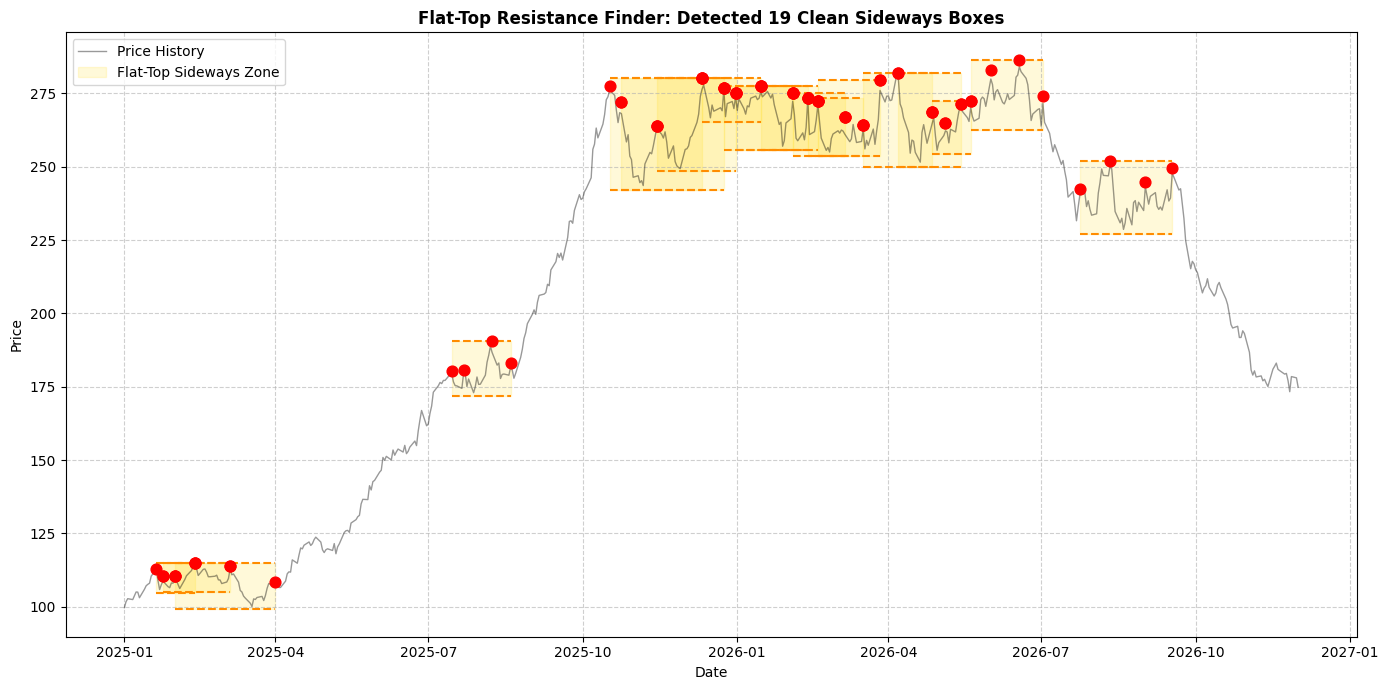

In [83]:
# Generate data and run the flat-top sideways hunter
market_df = generate_stochastic_trend_ohlcv(days=500, seed=None)
find_flat_tops_and_boxes(market_df, window=7, max_slope_pct=0.04, max_peak_std_mult=1.5)

In [115]:
def backtest_sideways_box_strategy(df, window=7, max_slope_pct=0.04, max_peak_std_mult=1.5):
    """
    Causally correct flat-top sideways box backtester. 
    Boxes are identified retroactively, but trades are executed strictly 
    AFTER the 3rd peak confirms the box (no look-ahead bias).
    """
    highs = df['High']
    rolling_max = highs.rolling(window=window, center=True).max()
    peak_mask = (highs == rolling_max)
    peak_indices = np.where(peak_mask)[0]
    
    if len(peak_indices) < 3:
        print("Not enough peaks found with the current window size.")
        return

    # --- STEP 1: DETECT RAW CONFIRMED BOXES ---
    raw_boxes = []
    
    i = 0
    while i < len(peak_indices) - 2:
        chunk = peak_indices[i:i+3]
        peak_dates = df.index[chunk]
        peak_prices = highs.iloc[chunk].values
        
        days_span = (peak_dates[-1] - peak_dates[0]).days
        if days_span < 10 or days_span > 120:
            i += 1
            continue
            
        x = np.arange(len(peak_prices))
        slope, intercept = np.polyfit(x, peak_prices, 1)
        start_val = intercept
        end_val = intercept + slope * (len(peak_prices) - 1)
        slope_pct = abs((end_val - start_val) / start_val)
        
        fitted_line = intercept + slope * x
        peak_std = np.std(peak_prices - fitted_line)
        local_baseline_std = df['Close'].rolling(30).std().iloc[chunk[-1]]
        allowed_std = local_baseline_std * 0.5
        
        if slope_pct <= max_slope_pct and peak_std <= (allowed_std * max_peak_std_mult):
            top_price = peak_prices.max()
            
            # Bottom support is the lowest low up to the 3rd peak confirmation
            pre_sub_df = df.loc[peak_dates[0]:peak_dates[-1]]
            bottom_price = pre_sub_df['Low'].min()
            
            # Track box forward from the 3rd peak until a breakout occurs
            post_dates = df.index[df.index > peak_dates[-1]]
            end_box_date = peak_dates[-1]
            
            for date in post_dates:
                row = df.loc[date]
                if row['Close'] > top_price * 1.02 or row['Close'] < bottom_price * 0.98:
                    end_box_date = date
                    break
                end_box_date = date
                
            box_df = df.loc[peak_dates[-1]:end_box_date] # Trade zone starts AT/AFTER 3rd peak
            if len(box_df) >= 5:
                raw_boxes.append({
                    'start_vis': peak_dates[0],  # For drawing the box from peak 1
                    'start_trade': peak_dates[-1],# For executing trades strictly after peak 3
                    'end': end_box_date,
                    'top': top_price,
                    'bottom': bottom_price
                })
            i += max(1, len(chunk) - 1)
        else:
            i += 1

    if not raw_boxes:
        print("No valid sideways boxes found.")
        return

    # --- STEP 2: PLOT & BACKTEST CAUSALLY ---
    plt.figure(figsize=(14, 7))
    plt.plot(df.index, df['Close'], color='black', alpha=0.4, linewidth=1, label='Price History')
    
    trades = []
    
    for box in raw_boxes:
        # Draw visual box boundaries from 1st peak to breakout
        vis_df = df.loc[box['start_vis']:box['end']]
        plt.hlines(y=box['top'], xmin=vis_df.index[0], xmax=vis_df.index[-1], color='darkorange', linewidth=1.5, linestyle='--')
        plt.hlines(y=box['bottom'], xmin=vis_df.index[0], xmax=vis_df.index[-1], color='darkorange', linewidth=1.5, linestyle='--')
        plt.fill_between(vis_df.index, box['bottom'], box['top'], color='gold', alpha=0.10)
        
        # --- CAUSAL TRADE EXECUTION ---
        # Trades happen ONLY in the window AFTER the 3rd peak is confirmed
        trade_df = df.loc[box['start_trade']:box['end']]
        if len(trade_df) < 5:
            continue
            
        local_box_std = vis_df['Close'].std() # Volatility of the formed box
        in_position = False
        entry_price = 0.0
        stop_loss_price = 0.0
        target_price = 0.0
        
        for date, row in trade_df.iterrows():
            # BUY: Price tests bottom support floor (only after box is confirmed)
            if not in_position and row['Low'] <= box['bottom'] * 1.01:
                in_position = True
                entry_price = row['Close']
                
                # Strict Risk Rules: 0.67 std down stop loss, 2.0 std up target
                stop_loss_price = entry_price - (local_box_std * 0.67)
                target_price = entry_price + (local_box_std * 2.0)
                
                plt.scatter(date, entry_price, color='lime', s=100, marker='^', zorder=6)
                trades.append({'type': 'BUY', 'date': date, 'price': entry_price})
            
            elif in_position:
                # CHECK 1: Stop Loss Hit (Orange X)
                if row['Low'] <= stop_loss_price:
                    in_position = False
                    exit_price = stop_loss_price
                    plt.scatter(date, exit_price, color='orange', s=100, marker='x', zorder=6)
                    trades.append({'type': 'STOP_LOSS', 'date': date, 'price': exit_price})
                    
                # CHECK 2: Take Profit Hit (2.0 Std Up or Resistance) (Red Arrow)
                elif row['High'] >= box['top'] * 0.99 or row['High'] >= target_price:
                    in_position = False
                    exit_price = row['Close']
                    plt.scatter(date, exit_price, color='crimson', s=100, marker='v', zorder=6)
                    trades.append({'type': 'SELL', 'date': date, 'price': exit_price})

    plt.title(f'Causally-Correct Sideways Strategy: {len(raw_boxes)} Boxes | {len(trades)} Trades Executed', fontsize=12, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Price')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

In [122]:
market_df = generate_stochastic_trend_ohlcv(days=500, seed=None)

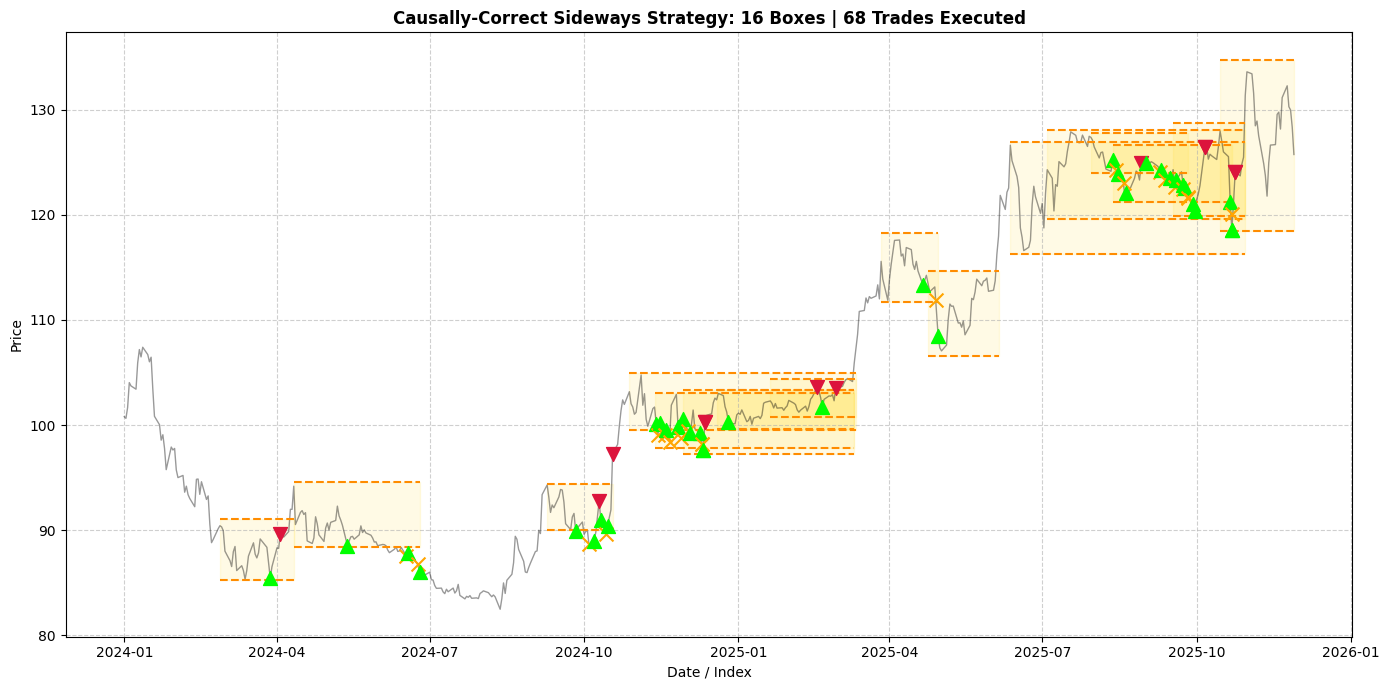

In [125]:
backtest_sideways_box_strategy(market_df, window=7, max_slope_pct=0.04, max_peak_std_mult=1.5)